# Laya: does more data help? + fixing the boundary question (Kaggle, GPU T4 ×2)

Second run on `laya_v1`, after `laya-wahy-finetuning-finished.ipynb`. It answers two questions in one background commit:

**1. Learning curve: is more data worth generating?** The same recipe (soft labels, data as is) trained on 25 / 50 / 75 / 100 %
of the training lectures. If the test score still climbs from 75 % to 100 %, more data will help; if it is flat, generating more of
the same will not, and the effort should go to other fixes (hard cases, the errors, the boundary).

**2. The boundary question collapsed** in the first run: every model answered `COMPLETE_SPAN` for every quote. Why: 81 % of the
training boundary labels are `COMPLETE_SPAN` (Sonnet marks 84–87 % of its quotes complete), so "always complete" is the cheapest
answer, and on val (86 % complete) it even scores 86 % accuracy, which hid the problem. The runs `bnd_x3` / `bnd_x6` repeat every
*cut-off* boundary item 3× / 6× in training, so the model can no longer win by ignoring them. Verdict items are untouched.

| run | training data | boundary repeats | question it answers |
|---|---|---|---|
| `curve_100` | all 57 training lectures (2,863 rows) | – | the reference: soft_asis at 2 epochs |
| `bnd_x3` | same | cut-off items ×3 (42 % of boundary items) | does oversampling fix the boundary? |
| `bnd_x6` | same | cut-off items ×6 (59 %) | more of it: better, or now too eager? |
| `curve_25` / `_50` / `_75` | ¼, ½, ¾ of the lectures (nested) | – | the learning curve |

What changed vs the first run: **2 epochs** instead of 4 (val loss was lowest at epoch 2), the boundary is scored with
**balanced accuracy** (mean recall of the 4 classes: "always complete" = 0.25, not 0.86), and a **no-model word-overlap rule**
is scored next to the models as the bar to beat. Val and test are the same files as before, so the numbers compare directly.

### Kaggle settings (right-hand panel)
* **Accelerator:** `GPU T4 x2` · **Internet:** `On` · **Secrets:** `HF_TOKEN` (only if `PUSH_TO_HUB`)
* **Input:** the `laya_v1` dataset, **new version** with the updated `train_ddp.py` / `eval_laya.py` (section 3 checks it)
* **Run:** *Save Version → Save & Run All (Commit)*, browser can be closed. Expect **~1 h 45 min** (6 trainings, 6 evaluations).
  The order puts `curve_100`, `bnd_x3`, `bnd_x6` first, so a session that dies late still has the boundary answer.

## 1. Environment & dual T4 GPU check

In [1]:
!nvidia-smi
import os, subprocess, torch

n_gpu = torch.cuda.device_count()
print(f"CUDA Available: {torch.cuda.is_available()} | Visible GPUs: {n_gpu}")
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} ({p.total_memory / 1e9:.1f} GB)")

assert n_gpu >= 2, (
    f"Expected 2 GPUs, but detected {n_gpu}! Notebook options -> Accelerator -> GPU T4 x2."
)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

Mon Oct 26 14:42:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies

In [2]:
# pinned to the 0.4 line the Wahy data was validated with (laya.train / laya.calibrate are identical 0.4.12 -> 0.4.15)
!pip install -q -U "laya>=0.4.12,<0.5" "transformers>=4.48.0" safetensors huggingface_hub pandas matplotlib tabulate
import laya, transformers
print("Laya version        :", laya.__version__)
print("Transformers version:", transformers.__version__)
print("PyTorch version     :", torch.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2

## 3. Dataset, scripts and the base checkpoint
Stops early if the dataset is still the first version: this run needs `--boundary-oversample` in `train_ddp.py` and the
boundary rule in `eval_laya.py`.

In [3]:
import glob, json, sys
from pathlib import Path
from huggingface_hub import snapshot_download
from laya.agent import _fix_tokenizer_config

DATA = next(Path(p).parent for p in sorted(glob.glob("/kaggle/input/**/manifest.json", recursive=True))
            if json.loads(Path(p).read_text()).get("name") == "laya_v1")
assert "--boundary-oversample" in (DATA / "train_ddp.py").read_text() and "def rule_boundary" in (DATA / "eval_laya.py").read_text(), (
    "Old scripts in the dataset: upload the rebuilt laya_v1.zip as a NEW VERSION of the dataset (see the guide), then re-run.")

manifest = json.loads((DATA / "manifest.json").read_text())
sys.path.insert(0, str(DATA))
import eval_laya

print("dataset:", DATA, "| created", manifest["created"], "| base model", manifest["base_model"])
MODEL_ID = manifest["base_model"]          # convaiinnovations/laya-multilingual
model_dir = snapshot_download(MODEL_ID)
_fix_tokenizer_config(model_dir)
print("base checkpoint:", model_dir, json.loads(Path(model_dir, "rl_agent_config.json").read_text())["encoder"])

dataset: /kaggle/input/datasets/abderrahimzineddine/laya-v1/laya_v1 | created 2026-10-25 | base model convaiinnovations/laya-multilingual


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

base checkpoint: /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 jhu-clsp/mmBERT-base


## 4. Settings
`RUNS` runs in this order; a failing run is logged and the next one still runs. Everything else is the first run's recipe
(effective batch 64, RLCD, the same learning rates), so the only differences are the ones in the table above.

In [4]:
RUNS = {   # name -> (training subset, boundary oversample)
    "curve_100": ("curve_100", 1),
    "bnd_x3":    ("curve_100", 3),
    "bnd_x6":    ("curve_100", 6),
    "curve_25":  ("curve_25", 1),
    "curve_50":  ("curve_50", 1),
    "curve_75":  ("curve_75", 1),
}
TRAIN_ARGS = "--epochs 2 --micro-batch 8 --grad-accum 4 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd"
APP_FALSE_SHARE = 0.10      # the app's real stream is ~10 % "not a quote" (prior-corrected numbers)
SEED = 20261026             # which lectures go into the 25 / 50 / 75 % subsets
KEEP_WEIGHTS = {"curve_100", "bnd_x3", "bnd_x6"}   # the curve_25/50/75 weights are deleted after evaluation (~1.2 GB each)
PUSH_TO_HUB = True          # upload the KEEP_WEIGHTS models to PRIVATE Hub repos (needs the HF_TOKEN secret)
HUB_PREFIX = "ZenoAbderrahim/laya-wahy-lc"          # repo = f"{HUB_PREFIX}-{run}"
# first run (laya-wahy-finetuning-finished.ipynb), soft_asis at 4 epochs: the dashed reference line in the plots
V1_SOFT_ASIS = {"you · accuracy": 0.914, "you · AUC": 0.944, "you · real wrongly rejected": 0.064,
                "you + Sonnet · AUC": 0.960, "you + Sonnet · accuracy": 0.909, "you · boundary balanced acc": 0.25}

WORK = Path("/kaggle/working")
for d in ("results", "logs", "data"):
    (WORK / d).mkdir(parents=True, exist_ok=True)

def run(cmd, log):
    # Run a shell command, stream its output here and into a log file; returns the exit code.
    print("$", cmd, flush=True)
    with open(log, "w") as f:
        p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            f.write(line)
            if "Warning" not in line and "warn(" not in line:
                print(line, end="", flush=True)
        return p.wait()

## 5. The 25 / 50 / 75 % subsets
Whole lectures, as in the split (a lecture's findings are near-copies of each other). **Nested**: the 50 % lectures contain the
25 % ones and so on, so each step only *adds* data. **Stratified**: the 9 review lessons (the only ones with your labels) and the
48 batch lectures are subsampled separately, so every subset has the same mix of your labels and Sonnet's. Val and test do not
change.

In [5]:
import random
from collections import defaultdict

train_rows = eval_laya.read_jsonl(DATA / "soft_asis" / "train.jsonl")
docs = defaultdict(list)
for r in train_rows:
    docs[(r["meta"]["group"], r["meta"]["doc_id"])].append(r)
by_group = defaultdict(list)
for g, d in sorted(docs):
    by_group[g].append(d)
rng = random.Random(SEED)
for g in by_group:
    rng.shuffle(by_group[g])        # one order per group; a fraction takes its first lectures, so the subsets are nested

def describe(rows):
    b = [r["meta"]["boundary"] for r in rows if r["meta"]["boundary"]]
    return {"lectures": len({r["meta"]["doc_id"] for r in rows}), "rows": len(rows),
            "your labels": sum(r["meta"]["source"] == "user" for r in rows),
            "not a quote": round(sum(r["meta"]["verdict"] == "FALSE" for r in rows) / len(rows), 4),
            "boundary items": len(b), "cut-off boundary items": sum(x != "COMPLETE_SPAN" for x in b)}

subsets, false_share = {}, {}
for pct in (25, 50, 75, 100):
    keep = {d for g, ds in by_group.items() for d in ds[:max(1, round(len(ds) * pct / 100))]}
    rows = [r for r in train_rows if r["meta"]["doc_id"] in keep]
    path = WORK / "data" / f"curve_{pct}.jsonl"
    with open(path, "w", encoding="utf-8") as f:
        f.writelines(json.dumps(r, ensure_ascii=False) + "\n" for r in rows)
    subsets[f"curve_{pct}"] = describe(rows)
    false_share[f"curve_{pct}"] = subsets[f"curve_{pct}"]["not a quote"]

import pandas as pd
pd.DataFrame(subsets).T

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,lectures,rows,your labels,not a quote,boundary items,cut-off boundary items
curve_25,14.0,886.0,52.0,0.4300,498.0,75.0
curve_50,28.0,1388.0,65.0,0.4719,726.0,115.0
curve_75,43.0,2068.0,101.0,0.4768,1069.0,182.0
curve_100,57.0,2863.0,197.0,0.4852,1443.0,281.0


## 6. Train + evaluate
Per run: `torchrun` trains on both GPUs, then `eval_laya.py` scores the model on the full test set. The val line after each
epoch now also prints the boundary's **balanced** accuracy: it should climb above 0.25 for the `bnd_*` runs.

In [6]:
import time
status = {}
for name, (subset, oversample) in RUNS.items():
    out = WORK / "models" / name
    t0 = time.time()
    try:
        rc = run(f"torchrun --standalone --nproc_per_node=2 {DATA}/train_ddp.py {model_dir} {out} "
                 f"--train {WORK}/data/{subset}.jsonl --val {DATA}/soft_asis/val.jsonl --name laya-wahy-{name} "
                 f"--boundary-oversample {oversample} {TRAIN_ARGS}", WORK / "logs" / f"train_{name}.log")
        if rc != 0 or not (out / "model.safetensors").exists():
            status[name] = f"training failed (exit {rc}), see logs/train_{name}.log"
            continue
        baselines = f"--baselines {DATA}/baselines.json" if name == "curve_100" else ""   # JEV / Gemini lines, once
        rc = run(f"python {DATA}/eval_laya.py predict --model {out} --name {name} --test {DATA}/test.jsonl "
                 f"--out {WORK}/results/{name}.json --train-false-share {false_share[subset]} "
                 f"--app-false-share {APP_FALSE_SHARE} --batch-size 32 {baselines}", WORK / "logs" / f"eval_{name}.log")
        status[name] = f"ok in {(time.time() - t0) / 60:.0f} min" if rc == 0 else f"evaluation failed (exit {rc})"
        if rc == 0 and name not in KEEP_WEIGHTS:
            (out / "model.safetensors").unlink()          # keep train_log.json and the config, drop the weights
    except Exception as e:
        status[name] = f"error: {e}"
    print(f"\n##### {name}: {status[name]}\n", flush=True)
json.dump(status, open(WORK / "results" / "status.json", "w"), indent=1)
status

$ torchrun --standalone --nproc_per_node=2 /kaggle/input/datasets/abderrahimzineddine/laya-v1/laya_v1/train_ddp.py /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 /kaggle/working/models/curve_100 --train /kaggle/working/data/curve_100.jsonl --val /kaggle/input/datasets/abderrahimzineddine/laya-v1/laya_v1/soft_asis/val.jsonl --name laya-wahy-curve_100 --boundary-oversample 1 --epochs 2 --micro-batch 8 --grad-accum 4 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd
W1026 14:43:29.087000 102 torch/distributed/run.py:851] 
W1026 14:43:29.087000 102 torch/distributed/run.py:851] *****************************************
W1026 14:43:29.087000 102 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1026 14:43:29.087000 102 torch/dist

{'curve_100': 'ok in 20 min',
 'bnd_x3': 'ok in 21 min',
 'bnd_x6': 'ok in 24 min',
 'curve_25': 'ok in 12 min',
 'curve_50': 'ok in 14 min',
 'curve_75': 'ok in 16 min'}

## 7. Load the results (+ the two no-model boundary baselines)

In [7]:
from IPython.display import Markdown, display
test_rows = eval_laya.read_jsonl(DATA / "test.jsonl")
res = {n: json.load(open(WORK / "results" / f"{n}.json")) for n in RUNS if (WORK / "results" / f"{n}.json").exists()}
always_complete = {r["id"]: {"boundary_status": {b: float(b == "COMPLETE_SPAN") for b in eval_laya.BOUNDARIES}} for r in test_rows}
boundary_baselines = [eval_laya.evaluate(test_rows, always_complete, "always COMPLETE_SPAN (= the first run)"),
                      eval_laya.evaluate(test_rows, eval_laya.rule_predictions(test_rows), "word-overlap rule (no model)")]
teachers = [json.load(open(f)) for f in sorted(glob.glob(str(WORK / "results" / "baseline_*.json")))]
logs = {n: json.load(open(WORK / "models" / n / "train_log.json")) for n in RUNS if (WORK / "models" / n / "train_log.json").exists()}
print("results:", list(res), "| teacher baselines:", [t["name"] for t in teachers])

results: ['curve_100', 'bnd_x3', 'bnd_x6', 'curve_25', 'curve_50', 'curve_75'] | teacher baselines: ['7 shallow fields (LR)', 'Gemini (cached)', 'JEV (cached)', 'Laya (base) (cached)', 'span length only (LR)']


## 8. Question 1: the learning curve
x = training rows (25 → 100 %), one line per score. The dashed line is the first run's soft_asis (4 epochs) for reference.
**Read it like this:** if the last segment (75 → 100 %) still rises by more than the noise (~1–2 points; one seed per point),
more data helps and generating it is worth it. If it is flat, the model has taken what this kind of data can give.

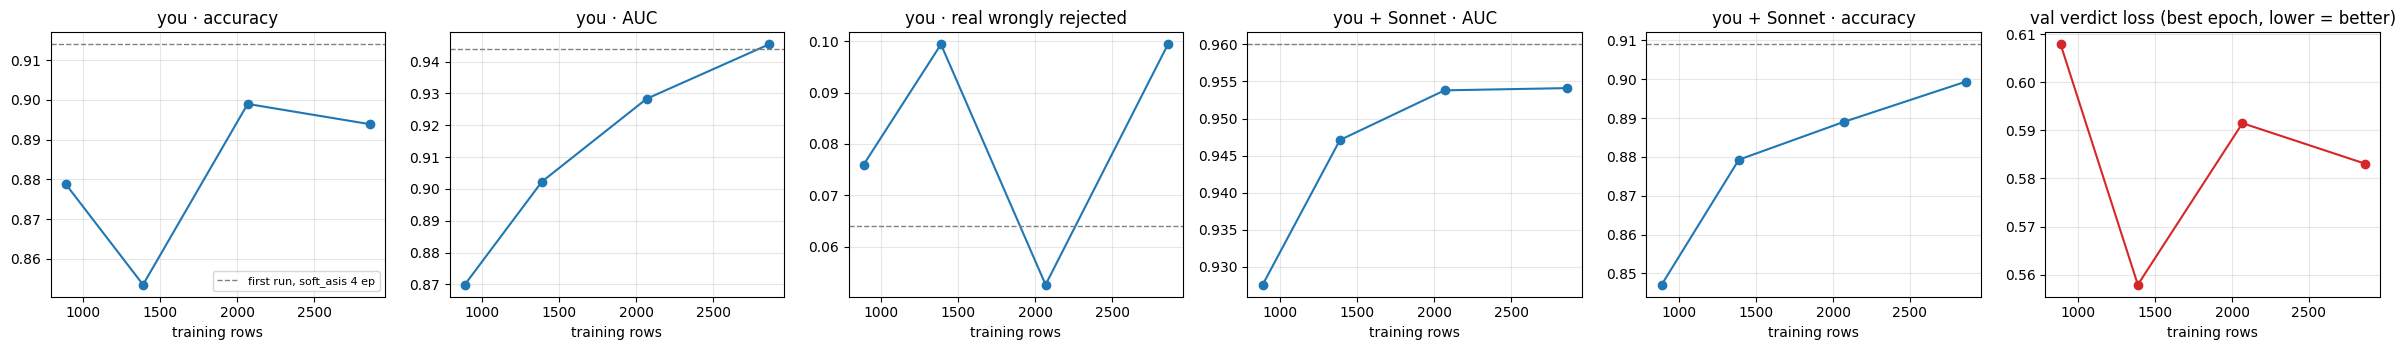

,train rows,lectures,you · accuracy,you · AUC,you · real wrongly rejected,you · not-a-quote recall,you+Sonnet · AUC,you+Sonnet · accuracy
run,,,,,,,,
curve_25,886,14,87.9 % [83–92],0.8699,7.6 % [4–13],59.3 % [41–75],0.9276,84.7 % [83–87]
curve_50,1388,28,85.4 % [80–90],0.9023,9.9 % [6–15],55.6 % [37–72],0.9471,87.9 % [86–90]
curve_75,2068,43,89.9 % [85–93],0.9283,5.3 % [3–10],59.3 % [41–75],0.9538,88.9 % [87–91]
curve_100,2863,57,89.4 % [84–93],0.9454,9.9 % [6–15],85.2 % [68–94],0.9541,89.9 % [88–91]


In [8]:
import matplotlib.pyplot as plt
curve = [n for n in ("curve_25", "curve_50", "curve_75", "curve_100") if n in res]
x = [subsets[n]["rows"] for n in curve]

def score(n, group, key, part="verdict"):
    v = (res[n]["groups"].get(group) or {}).get(part) or {}
    s = v.get(key)
    return s[0] if isinstance(s, list) else s

panels = [("you", "accuracy", "you · accuracy"), ("you", "AUC P(not a quote)", "you · AUC"),
          ("you", "real quotes wrongly rejected", "you · real wrongly rejected"),
          ("you + Sonnet", "AUC P(not a quote)", "you + Sonnet · AUC"), ("you + Sonnet", "accuracy", "you + Sonnet · accuracy")]
fig, ax = plt.subplots(1, len(panels) + 1, figsize=(4 * (len(panels) + 1), 3.6))
for a, (g, k, title) in zip(ax, panels):
    a.plot(x, [score(n, g, k) for n in curve], marker="o")
    a.axhline(V1_SOFT_ASIS[title], ls="--", c="grey", lw=1, label="first run, soft_asis 4 ep")
    a.set(title=title, xlabel="training rows"); a.grid(alpha=.3)
best_val = [min(e["val"]["verdict"]["loss"] for e in logs[n]["epochs"]) if n in logs else None for n in curve]
ax[-1].plot(x, best_val, marker="o", c="C3"); ax[-1].set(title="val verdict loss (best epoch, lower = better)", xlabel="training rows")
ax[-1].grid(alpha=.3); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(WORK / "results" / "learning_curve.png", dpi=120); plt.show()

table = []
for n in curve:
    v = res[n]["groups"]["you"]["verdict"]; vs = res[n]["groups"]["you + Sonnet"]["verdict"]
    table.append({"run": n, "train rows": subsets[n]["rows"], "lectures": subsets[n]["lectures"],
                  "you · accuracy": eval_laya._fmt(v["accuracy"]), "you · AUC": v["AUC P(not a quote)"],
                  "you · real wrongly rejected": eval_laya._fmt(v["real quotes wrongly rejected"]),
                  "you · not-a-quote recall": eval_laya._fmt(v["not-a-quote recall"]),
                  "you+Sonnet · AUC": vs["AUC P(not a quote)"], "you+Sonnet · accuracy": eval_laya._fmt(vs["accuracy"])})
display(pd.DataFrame(table).set_index("run"))

## 9. Question 2: the boundary
**Balanced accuracy** is the column to read (mean recall of the 4 classes): "always complete" scores 0.25 whatever the class
mix, a model that catches cut-off quotes scores more. *Cut-off quotes caught* = of the quotes the labeller marked as cut off
(any `MISSING_*`), how many the model also flags as not complete: the part that matters for the app (it decides whether to
extend the span). The rule row is the bar: a model below it has not learned more than word matching.

On **your** cards the boundary is judged more strictly than Sonnet does (45 % complete vs 84–87 % on the same engines), so a
model trained on Sonnet's labels will under-flag cut-offs on your cards; *written text* is a second, independent judge.

In [9]:
order = ["curve_100", "bnd_x3", "bnd_x6", "curve_25", "curve_50", "curve_75"]
models = [res[n] for n in order if n in res]
btext = []
for g in ["you", "written text", "you + Sonnet", "Sonnet · other lectures"]:
    t = f"### boundary · {g}\n" + eval_laya.compare_boundary(boundary_baselines + teachers + models, g)
    btext.append(t); display(Markdown(t))
(WORK / "results" / "boundary.md").write_text("\n\n".join(btext))

# val after each epoch: did the boundary start learning, and when?
display(pd.DataFrame([{"run": n, **{f"epoch {e['epoch']} · balanced": e["val"]["boundary"].get("balanced_accuracy") for e in logs[n]["epochs"]},
                       **{f"epoch {e['epoch']} · accuracy": round(e["val"]["boundary"]["accuracy"], 4) for e in logs[n]["epochs"]}}
                      for n in order if n in logs]).set_index("run"))

### boundary · you
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH |
|---|---|---|---|---|---|---|---|---|
| always COMPLETE_SPAN (= the first run) | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] |
| word-overlap rule (no model) | 143 | 60.8 % [53–68] | **0.506** | 64.6 % [54–74] | 85.9 % [75–92] | 39.1 % [22–59] | 47.2 % [32–63] | 30.0 % [15–52] |
| Gemini (cached) | 102 | 50.0 % [40–60] | **0.396** | 31.8 % [22–44] | 94.9 % [83–99] | 22.2 % [9–45] | 30.8 % [16–50] | 10.5 % [3–31] |
| JEV (cached) | 102 | 52.9 % [43–62] | **0.424** | 33.3 % [23–46] | 100.0 % [91–100] | 11.1 % [3–33] | 26.9 % [14–46] | 31.6 % [15–54] |
| Laya (base) (cached) | 102 | 30.4 % [22–40] | **0.293** | 60.3 % [48–71] | 43.6 % [29–59] | 0.0 % [0–18] | 0.0 % [0–13] | 73.7 % [51–88] |
| curve_100 | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] |
| bnd_x3 | 143 | 44.8 % [37–53] | **0.284** | 17.7 % [11–28] | 90.6 % [81–96] | 17.4 % [7–37] | 5.6 % [2–18] | 0.0 % [0–16] |
| bnd_x6 | 143 | 48.9 % [41–57] | **0.349** | 30.4 % [21–41] | 84.4 % [74–91] | 30.4 % [16–51] | 25.0 % [14–41] | 0.0 % [0–16] |
| curve_25 | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] |
| curve_50 | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] |
| curve_75 | 143 | 44.8 % [37–53] | **0.250** | 0.0 % [0–5] | 100.0 % [94–100] | 0.0 % [0–14] | 0.0 % [0–10] | 0.0 % [0–16] |

### boundary · written text
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH |
|---|---|---|---|---|---|---|---|---|
| always COMPLETE_SPAN (= the first run) | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] |
| word-overlap rule (no model) | 271 | 76.4 % [71–81] | **0.673** | 77.5 % [68–84] | 84.6 % [78–89] | 60.5 % [46–74] | 69.2 % [54–81] | 55.0 % [34–74] |
| curve_100 | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] |
| bnd_x3 | 271 | 63.5 % [58–69] | **0.303** | 20.6 % [14–29] | 95.3 % [91–98] | 23.3 % [13–38] | 2.6 % [0–13] | 0.0 % [0–16] |
| bnd_x6 | 271 | 64.6 % [59–70] | **0.369** | 43.1 % [34–53] | 89.3 % [84–93] | 30.2 % [19–45] | 28.2 % [17–44] | 0.0 % [0–16] |
| curve_25 | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] |
| curve_50 | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] |
| curve_75 | 271 | 62.4 % [56–68] | **0.250** | 0.0 % [0–4] | 100.0 % [98–100] | 0.0 % [0–8] | 0.0 % [0–9] | 0.0 % [0–16] |

### boundary · you + Sonnet
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH |
|---|---|---|---|---|---|---|---|---|
| always COMPLETE_SPAN (= the first run) | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] |
| word-overlap rule (no model) | 634 | 68.9 % [65–72] | **0.426** | 47.0 % [40–54] | 85.1 % [81–88] | 31.1 % [22–42] | 30.2 % [22–41] | 24.0 % [12–43] |
| Gemini (cached) | 133 | 51.9 % [43–60] | **0.360** | 28.2 % [19–40] | 88.7 % [78–94] | 19.1 % [8–40] | 25.8 % [14–43] | 10.5 % [3–31] |
| JEV (cached) | 133 | 54.9 % [46–63] | **0.401** | 31.0 % [21–42] | 91.9 % [82–97] | 14.3 % [5–35] | 22.6 % [11–40] | 31.6 % [15–54] |
| Laya (base) (cached) | 102 | 30.4 % [22–40] | **0.293** | 60.3 % [48–71] | 43.6 % [29–59] | 0.0 % [0–18] | 0.0 % [0–13] | 73.7 % [51–88] |
| curve_100 | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] |
| bnd_x3 | 634 | 63.6 % [60–67] | **0.304** | 30.3 % [24–37] | 83.3 % [80–86] | 33.8 % [24–45] | 4.7 % [2–11] | 0.0 % [0–13] |
| bnd_x6 | 634 | 64.5 % [61–68] | **0.340** | 38.4 % [32–46] | 81.3 % [77–85] | 24.3 % [16–35] | 30.2 % [22–41] | 0.0 % [0–13] |
| curve_25 | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] |
| curve_50 | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] |
| curve_75 | 634 | 70.8 % [67–74] | **0.250** | 0.0 % [0–2] | 100.0 % [99–100] | 0.0 % [0–5] | 0.0 % [0–4] | 0.0 % [0–13] |

### boundary · Sonnet · other lectures
| model | cards | accuracy | **balanced accuracy** | cut-off quotes caught | COMPLETE_SPAN | MISSING_START | MISSING_END | MISSING_BOTH |
|---|---|---|---|---|---|---|---|---|
| always COMPLETE_SPAN (= the first run) | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] |
| word-overlap rule (no model) | 329 | 79.6 % [75–84] | **0.374** | 34.5 % [24–47] | 90.4 % [86–93] | 33.3 % [19–51] | 25.9 % [13–45] | 0.0 % [0–79] |
| curve_100 | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] |
| bnd_x3 | 329 | 75.1 % [70–79] | **0.311** | 36.2 % [25–49] | 87.1 % [83–91] | 30.0 % [17–48] | 7.4 % [2–23] | 0.0 % [0–79] |
| bnd_x6 | 329 | 75.4 % [70–80] | **0.365** | 37.9 % [27–51] | 85.2 % [81–89] | 20.0 % [10–37] | 40.7 % [25–59] | 0.0 % [0–79] |
| curve_25 | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] |
| curve_50 | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] |
| curve_75 | 329 | 82.4 % [78–86] | **0.250** | 0.0 % [0–6] | 100.0 % [99–100] | 0.0 % [0–11] | 0.0 % [0–12] | 0.0 % [0–79] |

,epoch 1 · balanced,epoch 2 · balanced,epoch 1 · accuracy,epoch 2 · accuracy
run,,,,
curve_100,0.2500,0.2500,0.8561,0.8561
bnd_x3,0.2575,0.3237,0.8447,0.7386
bnd_x6,0.3325,0.3104,0.5341,0.7045
curve_25,0.2500,0.2500,0.8561,0.8561
curve_50,0.2500,0.2500,0.8561,0.8561
curve_75,0.2500,0.2500,0.8561,0.8561


In [10]:
# confusion matrices on your cards (rows = your label, columns = the model's answer)
for n in ("curve_100", "bnd_x3", "bnd_x6"):
    b = (res.get(n, {}).get("groups", {}).get("you") or {}).get("boundary")
    if b:
        display(Markdown(f"#### {n}"))
        display(pd.DataFrame(b["confusion (gold -> predicted)"]).T.rename_axis("you \\ model"))

#### curve_100

,COMPLETE_SPAN,MISSING_START,MISSING_END,MISSING_BOTH
you \ model,,,,
COMPLETE_SPAN,64,0,0,0
MISSING_START,23,0,0,0
MISSING_END,36,0,0,0
MISSING_BOTH,20,0,0,0


#### bnd_x3

,COMPLETE_SPAN,MISSING_START,MISSING_END,MISSING_BOTH
you \ model,,,,
COMPLETE_SPAN,58,6,0,0
MISSING_START,19,4,0,0
MISSING_END,31,3,2,0
MISSING_BOTH,15,5,0,0


#### bnd_x6

,COMPLETE_SPAN,MISSING_START,MISSING_END,MISSING_BOTH
you \ model,,,,
COMPLETE_SPAN,54,5,5,0
MISSING_START,15,7,1,0
MISSING_END,25,2,9,0
MISSING_BOTH,15,4,1,0


## 10. Did the oversampling cost anything on the verdict?
The boundary repeats change what the shared encoder sees, so check the verdict did not get worse. Same columns as the first run.

In [11]:
report = []
for g in ["you", "you + Sonnet", "Sonnet · other lectures", "written text"]:
    t = f"### verdict · {g}\n" + eval_laya.compare(models + teachers, g)
    report.append(t); display(Markdown(t))
(WORK / "results" / "comparison.md").write_text("\n\n".join(report))

for n in order:
    if n in logs:
        cal = logs[n].get("calibration", {})
        print(f"{n:10s} {logs[n]['seconds'] / 60:.0f} min | {logs[n]['train_items']} items ({logs[n].get('boundary_oversampled_items', 0)} boundary repeats) "
              f"| temperature {cal.get('temperature', ['?'])[0]} | issues {cal.get('report', {}).get('choice', {}).get('issues')}")

### verdict · you
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| curve_100 | 198 | 89.4 % [84–93] | 85.2 % [68–94] | 57.5 % [42–71] | 9.9 % [6–15] | 0.945 | 0.113 | 44.8 % [37–53] |
| bnd_x3 | 198 | 88.4 % [83–92] | 70.4 % [52–84] | 55.9 % [39–71] | 8.8 % [5–14] | 0.933 | 0.090 | 44.8 % [37–53] |
| bnd_x6 | 198 | 89.4 % [84–93] | 77.8 % [59–89] | 58.3 % [42–73] | 8.8 % [5–14] | 0.918 | 0.086 | 48.9 % [41–57] |
| curve_25 | 198 | 87.9 % [83–92] | 59.3 % [41–75] | 55.2 % [38–72] | 7.6 % [4–13] | 0.870 | 0.084 | 44.8 % [37–53] |
| curve_50 | 198 | 85.4 % [80–90] | 55.6 % [37–72] | 46.9 % [31–64] | 9.9 % [6–15] | 0.902 | 0.081 | 44.8 % [37–53] |
| curve_75 | 198 | 89.9 % [85–93] | 59.3 % [41–75] | 64.0 % [45–80] | 5.3 % [3–10] | 0.928 | 0.080 | 44.8 % [37–53] |
| 7 shallow fields (LR) | 198 | 83.8 % [78–88] | 66.7 % [48–81] | 43.9 % [30–59] | 13.5 % [9–19] | 0.857 | 0.040 | — |
| Gemini (cached) | 147 | 89.8 % [84–94] | 41.7 % [24–61] | 100.0 % [72–100] | 0.0 % [0–3] | 0.708 | 0.102 | 50.0 % [40–60] |
| JEV (cached) | 147 | 86.4 % [80–91] | 20.8 % [9–40] | 100.0 % [57–100] | 0.0 % [0–3] | 0.604 | 0.136 | 52.9 % [43–62] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 198 | 79.3 % [73–84] | 29.6 % [16–48] | 26.7 % [14–44] | 12.9 % [9–19] | 0.723 | 0.109 | — |

### verdict · you + Sonnet
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| curve_100 | 1243 | 89.9 % [88–91] | 94.7 % [93–96] | 85.4 % [82–88] | 14.2 % [12–17] | 0.954 | 0.077 | 70.8 % [67–74] |
| bnd_x3 | 1243 | 90.0 % [88–92] | 92.9 % [91–95] | 86.7 % [84–89] | 12.5 % [10–15] | 0.962 | 0.061 | 63.6 % [60–67] |
| bnd_x6 | 1243 | 89.9 % [88–91] | 91.7 % [89–94] | 87.2 % [84–90] | 11.8 % [10–14] | 0.950 | 0.082 | 64.5 % [61–68] |
| curve_25 | 1243 | 84.7 % [83–87] | 81.8 % [78–85] | 85.0 % [82–88] | 12.7 % [10–15] | 0.928 | 0.062 | 70.8 % [67–74] |
| curve_50 | 1243 | 87.9 % [86–90] | 90.9 % [88–93] | 84.5 % [81–87] | 14.6 % [12–18] | 0.947 | 0.073 | 70.8 % [67–74] |
| curve_75 | 1243 | 88.9 % [87–91] | 88.6 % [86–91] | 87.7 % [85–90] | 10.9 % [9–13] | 0.954 | 0.077 | 70.8 % [67–74] |
| 7 shallow fields (LR) | 1243 | 85.5 % [83–87] | 89.3 % [87–92] | 81.5 % [78–84] | 17.8 % [15–21] | 0.932 | 0.035 | — |
| Gemini (cached) | 180 | 90.0 % [85–94] | 38.5 % [22–57] | 90.9 % [62–98] | 0.7 % [0–4] | 0.689 | 0.100 | 51.9 % [43–60] |
| JEV (cached) | 180 | 87.2 % [82–91] | 19.2 % [9–38] | 83.3 % [44–97] | 0.7 % [0–4] | 0.593 | 0.128 | 54.9 % [46–63] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 1243 | 81.7 % [79–84] | 78.7 % [75–82] | 81.5 % [78–84] | 15.7 % [13–19] | 0.890 | 0.042 | — |

### verdict · Sonnet · other lectures
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| curve_100 | 596 | 90.9 % [88–93] | 94.4 % [91–97] | 86.6 % [82–90] | 11.8 % [9–16] | 0.956 | 0.077 | 82.4 % [78–86] |
| bnd_x3 | 596 | 89.9 % [87–92] | 92.9 % [89–95] | 85.8 % [81–89] | 12.5 % [9–16] | 0.960 | 0.054 | 75.1 % [70–79] |
| bnd_x6 | 596 | 90.6 % [88–93] | 92.5 % [89–95] | 87.3 % [83–91] | 10.9 % [8–15] | 0.950 | 0.084 | 75.4 % [70–80] |
| curve_25 | 596 | 85.2 % [82–88] | 82.8 % [78–87] | 84.0 % [79–88] | 12.8 % [10–17] | 0.935 | 0.078 | 82.4 % [78–86] |
| curve_50 | 596 | 89.3 % [87–92] | 92.5 % [89–95] | 84.9 % [80–89] | 13.4 % [10–17] | 0.953 | 0.075 | 82.4 % [78–86] |
| curve_75 | 596 | 89.6 % [87–92] | 89.1 % [85–92] | 87.8 % [83–91] | 10.0 % [7–14] | 0.954 | 0.083 | 82.4 % [78–86] |
| 7 shallow fields (LR) | 596 | 86.6 % [84–89] | 91.8 % [88–94] | 80.9 % [76–85] | 17.6 % [14–22] | 0.941 | 0.057 | — |
| span length only (LR) | 596 | 81.9 % [79–85] | 80.9 % [76–85] | 79.1 % [74–84] | 17.3 % [14–22] | 0.897 | 0.051 | — |

### verdict · written text
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| curve_100 | 280 | 90.7 % [87–94] | 83.3 % [44–97] | 16.7 % [7–34] | 9.1 % [6–13] | 0.870 | 0.068 | 62.4 % [56–68] |
| bnd_x3 | 280 | 91.4 % [88–94] | 83.3 % [44–97] | 17.9 % [8–36] | 8.4 % [6–12] | 0.807 | 0.065 | 63.5 % [58–69] |
| bnd_x6 | 280 | 90.0 % [86–93] | 83.3 % [44–97] | 15.6 % [7–32] | 9.8 % [7–14] | 0.863 | 0.091 | 64.6 % [59–70] |
| curve_25 | 280 | 92.9 % [89–95] | 50.0 % [19–81] | 15.0 % [5–36] | 6.2 % [4–10] | 0.797 | 0.102 | 62.4 % [56–68] |
| curve_50 | 280 | 89.6 % [86–93] | 66.7 % [30–90] | 12.9 % [5–29] | 9.8 % [7–14] | 0.800 | 0.082 | 62.4 % [56–68] |
| curve_75 | 280 | 90.7 % [87–94] | 83.3 % [44–97] | 16.7 % [7–34] | 9.1 % [6–13] | 0.869 | 0.071 | 62.4 % [56–68] |
| 7 shallow fields (LR) | 280 | 92.9 % [89–95] | 83.3 % [44–97] | 20.8 % [9–40] | 6.9 % [4–11] | 0.904 | 0.051 | — |
| span length only (LR) | 280 | 82.9 % [78–87] | 83.3 % [44–97] | 9.6 % [4–21] | 17.2 % [13–22] | 0.919 | 0.169 | — |

curve_100  17 min | 4306 items (0 boundary repeats) | temperature 1.2514129877090454 | issues []
bnd_x3     19 min | 4868 items (562 boundary repeats) | temperature 1.1653093099594116 | issues []
bnd_x6     22 min | 5710 items (1405 boundary repeats) | temperature 1.2978956699371338 | issues []
curve_25   9 min | 1384 items (0 boundary repeats) | temperature 1.119423508644104 | issues []
curve_50   11 min | 2114 items (0 boundary repeats) | temperature 1.1185271739959717 | issues []
curve_75   14 min | 3136 items (0 boundary repeats) | temperature 1.1892155408859253 | issues []


## 11. (Optional) Push the kept models to the Hugging Face Hub — private
Only the `KEEP_WEIGHTS` runs. Without `PUSH_TO_HUB`, download them from the version's **Output** tab (`models/<run>/`).

In [12]:
if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    from kaggle_secrets import UserSecretsClient
    api = HfApi(token=UserSecretsClient().get_secret("HF_TOKEN"))
    for n in RUNS:
        out = WORK / "models" / n
        if n not in KEEP_WEIGHTS or not (out / "model.safetensors").exists():
            continue
        repo = f"{HUB_PREFIX}-{n}"
        api.create_repo(repo, repo_type="model", private=True, exist_ok=True)
        api.upload_folder(folder_path=str(out), repo_id=repo, repo_type="model",
                          commit_message=f"laya-multilingual fine-tuned on Wahy laya_v1 ({n}, 2 epochs)")
        print("pushed", repo)

pushed ZenoAbderrahim/laya-wahy-lc-curve_100
pushed ZenoAbderrahim/laya-wahy-lc-bnd_x3
pushed ZenoAbderrahim/laya-wahy-lc-bnd_x6
